# Лабораторная работа 4

Tensorflow 2.x

1) Подготовка данных

2) Использование Keras Model API

3) Использование Keras Sequential + Functional API

https://www.tensorflow.org/tutorials

Для выполнения лабораторной работы необходимо установить tensorflow версии 2.0 или выше .

Рекомендуется использовать возможности Colab'а по обучению моделей на GPU.


Для локального запуска установите зависимости в окружение ядра Jupyter командой `%pip install tensorflow scikit-learn matplotlib` в отдельной ячейке. Встроенный набор Digits загружается без скачивания данных. Результаты ниже получены на CPU с TensorFlow 2.21.0.


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

%matplotlib inline

SEED = 42
tf.keras.utils.set_random_seed(SEED)
device = '/GPU:0' if tf.config.list_logical_devices('GPU') else '/CPU:0'
print('TensorFlow:', tf.__version__, '| устройство:', device)


TensorFlow: 2.21.0 | устройство: /CPU:0


# Подготовка данных
Загрузите набор данных из предыдущей лабораторной работы. 

In [2]:
digits = load_digits()
images = digits.data.astype(np.float32) / 16.0
labels = digits.target.astype(np.int32)
train_idx, test_idx = train_test_split(
    np.arange(len(labels)), test_size=0.25, random_state=SEED, stratify=labels)
train_idx, val_idx = train_test_split(
    train_idx, test_size=0.2, random_state=SEED, stratify=labels[train_idx])

mean_image = images[train_idx].mean(axis=0)
X_train, X_val, X_test = [
    (images[idx] - mean_image).reshape(-1, 8, 8, 1)
    for idx in (train_idx, val_idx, test_idx)
]
y_train, y_val, y_test = [labels[idx] for idx in (train_idx, val_idx, test_idx)]
input_shape = X_train.shape[1:]
num_classes = len(np.unique(y_train))
for split, x, y in [('train', X_train, y_train), ('val', X_val, y_val),
                    ('test', X_test, y_test)]:
    print(split, x.shape, y.shape)


train (1077, 8, 8, 1) (1077,)
val (270, 8, 8, 1) (270,)
test (450, 8, 8, 1) (450,)


In [3]:
class Dataset(object):
    def __init__(self, X, y, batch_size, shuffle=False):
        """
        Construct a Dataset object to iterate over data X and labels y
        
        Inputs:
        - X: Numpy array of data, of any shape
        - y: Numpy array of labels, of any shape but with y.shape[0] == X.shape[0]
        - batch_size: Integer giving number of elements per minibatch
        - shuffle: (optional) Boolean, whether to shuffle the data on each epoch
        """
        assert X.shape[0] == y.shape[0], 'Got different numbers of data and labels'
        self.X, self.y = X, y
        self.batch_size, self.shuffle = batch_size, shuffle

    def __iter__(self):
        N, B = self.X.shape[0], self.batch_size
        idxs = np.arange(N)
        if self.shuffle:
            np.random.shuffle(idxs)
        for i in range(0, N, B):
            batch = idxs[i:i+B]
            yield self.X[batch], self.y[batch]


train_dset = Dataset(X_train, y_train, batch_size=64, shuffle=True)
val_dset = Dataset(X_val, y_val, batch_size=64, shuffle=False)
test_dset = Dataset(X_test, y_test, batch_size=64)

In [4]:
# We can iterate through a dataset like this:
for t, (x, y) in enumerate(train_dset):
    print(t, x.shape, y.shape)
    if t > 5: break

0 (64, 8, 8, 1) (64,)
1 (64, 8, 8, 1) (64,)
2 (64, 8, 8, 1) (64,)
3 (64, 8, 8, 1) (64,)
4 (64, 8, 8, 1) (64,)
5 (64, 8, 8, 1) (64,)
6 (64, 8, 8, 1) (64,)


#  Keras Model Subclassing API


Для реализации собственной модели с помощью Keras Model Subclassing API необходимо выполнить следующие шаги:

1) Определить новый класс, который является наследником tf.keras.Model.

2) В методе __init__() определить все необходимые слои из модуля tf.keras.layer

3) Реализовать прямой проход в методе call() на основе слоев, объявленных в __init__()

Ниже приведен пример использования keras API для определения двухслойной полносвязной сети. 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras

In [5]:
class TwoLayerFC(tf.keras.Model):
    def __init__(self, hidden_size, num_classes):
        super(TwoLayerFC, self).__init__()        
        initializer = tf.initializers.VarianceScaling(scale=2.0)
        self.fc1 = tf.keras.layers.Dense(hidden_size, activation='relu',
                                   kernel_initializer=initializer)
        self.fc2 = tf.keras.layers.Dense(num_classes, activation='softmax',
                                   kernel_initializer=initializer)
        self.flatten = tf.keras.layers.Flatten()
    
    def call(self, x, training=False):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.fc2(x)
        return x


def test_TwoLayerFC():
    """ A small unit test to exercise the TwoLayerFC model above. """
    input_size, hidden_size, num_classes = 50, 42, 10
    x = tf.zeros((64, input_size))
    model = TwoLayerFC(hidden_size, num_classes)
    with tf.device(device):
        scores = model(x)
        print(scores.shape)
        
test_TwoLayerFC()

(64, 10)


Реализуйте трехслойную CNN для вашей задачи классификации. 

Архитектура сети:
    
1. Сверточный слой (5 x 5 kernels, zero-padding = 'same')
2. Функция активации ReLU 
3. Сверточный слой (3 x 3 kernels, zero-padding = 'same')
4. Функция активации ReLU 
5. Полносвязный слой 
6. Функция активации Softmax 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Conv2D

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dense

In [6]:
class ThreeLayerConvNet(tf.keras.Model):
    def __init__(self, channel_1, channel_2, num_classes):
        super().__init__()
        self.conv1 = tf.keras.layers.Conv2D(channel_1, 5, padding='same',
                                            activation='relu', kernel_initializer='he_normal')
        self.conv2 = tf.keras.layers.Conv2D(channel_2, 3, padding='same',
                                            activation='relu', kernel_initializer='he_normal')
        self.flatten = tf.keras.layers.Flatten()
        self.classifier = tf.keras.layers.Dense(num_classes, activation='softmax')

    def call(self, x, training=False):
        return self.classifier(self.flatten(self.conv2(self.conv1(x))))


In [7]:
def test_ThreeLayerConvNet():    
    channel_1, channel_2, num_classes = 12, 8, 10
    model = ThreeLayerConvNet(channel_1, channel_2, num_classes)
    with tf.device(device):
        x = tf.zeros((64, *input_shape))
        scores = model(x)
        assert scores.shape == (64, num_classes)
        np.testing.assert_allclose(tf.reduce_sum(scores, axis=1), 1.0, atol=1e-6)
        print(scores.shape)

test_ThreeLayerConvNet()

(64, 10)


Пример реализации процесса обучения:

In [8]:
def evaluate_batches(model, dataset, loss_fn):
    loss_metric = tf.keras.metrics.Mean()
    accuracy = tf.keras.metrics.SparseCategoricalAccuracy()
    for x, y in dataset:
        scores = model(x, training=False)
        loss_metric.update_state(loss_fn(y, scores))
        accuracy.update_state(y, scores)
    return float(loss_metric.result()), float(accuracy.result())


def train_part34(model_init_fn, optimizer_init_fn, num_epochs=1):
    """Обучение через GradientTape и выбор эпохи по validation accuracy."""
    with tf.device(device):
        model = model_init_fn()
        optimizer = optimizer_init_fn()
        loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(reduction='none')
        history = {key: [] for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']}
        best_val = -1.0
        for epoch in range(num_epochs):
            train_loss = tf.keras.metrics.Mean()
            train_accuracy = tf.keras.metrics.SparseCategoricalAccuracy()
            for x, y in train_dset:
                with tf.GradientTape() as tape:
                    scores = model(x, training=True)
                    per_sample = loss_fn(y, scores)
                    loss = tf.reduce_mean(per_sample)
                    if model.losses:
                        loss += tf.add_n(model.losses)
                gradients = tape.gradient(loss, model.trainable_variables)
                optimizer.apply_gradients(zip(gradients, model.trainable_variables))
                train_loss.update_state(per_sample)
                train_accuracy.update_state(y, scores)

            val_loss, val_acc = evaluate_batches(model, val_dset, loss_fn)
            history['loss'].append(float(train_loss.result()))
            history['accuracy'].append(float(train_accuracy.result()))
            history['val_loss'].append(val_loss)
            history['val_accuracy'].append(val_acc)
            if val_acc > best_val:
                best_val = val_acc
                best_weights = model.get_weights()
            print(f'Эпоха {epoch+1:2d}: loss={history["loss"][-1]:.4f}, '
                  f'train={history["accuracy"][-1]:.2%}, val={val_acc:.2%}')

        model.set_weights(best_weights)
        return model, history


def keras_dataset(x, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        ds = ds.shuffle(len(y), seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return ds.batch(64).with_options(options)


def fit_compiled(model_init_fn, optimizer_init_fn, epochs):
    tf.keras.utils.set_random_seed(SEED)
    with tf.device(device):
        model = model_init_fn()
        model.compile(optimizer=optimizer_init_fn(),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        fit = model.fit(keras_dataset(X_train, y_train, shuffle=True), epochs=epochs,
                        validation_data=keras_dataset(X_val, y_val), verbose=2)
    return model, fit.history


In [9]:
hidden_size, num_classes = 128, 10
learning_rate = 1e-2

def model_init_fn():
    return TwoLayerFC(hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

fc_subclass, fc_subclass_history = train_part34(model_init_fn, optimizer_init_fn, num_epochs=5)

Эпоха  1: loss=2.3112, train=7.24%, val=7.04%
Эпоха  2: loss=2.2465, train=10.68%, val=11.48%
Эпоха  3: loss=2.1843, train=14.95%, val=17.04%
Эпоха  4: loss=2.1241, train=21.17%, val=22.22%
Эпоха  5: loss=2.0661, train=28.51%, val=31.11%


Обучите трехслойную CNN. В tf.keras.optimizers.SGD укажите Nesterov momentum = 0.9 . 

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/optimizers/SGD

Значение accuracy на валидационной выборке после 1 эпохи обучения должно быть > 50% .

In [10]:
learning_rate = 0.025
channel_1, channel_2 = 32, 16

def model_init_fn():
    return ThreeLayerConvNet(channel_1, channel_2, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9,
                                   nesterov=True)

tf.keras.utils.set_random_seed(SEED)
cnn_subclass, cnn_subclass_history = train_part34(model_init_fn, optimizer_init_fn)
print(f'Валидация после первой эпохи: {cnn_subclass_history["val_accuracy"][0]:.2%}')


Эпоха  1: loss=1.3672, train=61.65%, val=90.37%
Валидация после первой эпохи: 90.37%


# Использование Keras Sequential API для реализации последовательных моделей.

Пример для полносвязной сети:

In [11]:
learning_rate = 1e-2

def model_init_fn():
    hidden_layer_size, num_classes = 128, 10
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    layers = [
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hidden_layer_size, activation='relu',
                              kernel_initializer=initializer),
        tf.keras.layers.Dense(num_classes, activation='softmax', 
                              kernel_initializer=initializer),
    ]
    model = tf.keras.Sequential(layers)
    return model

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate) 

fc_seq, fc_seq_history = train_part34(model_init_fn, optimizer_init_fn, num_epochs=5)

Эпоха  1: loss=2.2316, train=20.52%, val=22.96%
Эпоха  2: loss=2.1719, train=24.61%, val=27.78%
Эпоха  3: loss=2.1142, train=29.81%, val=31.48%
Эпоха  4: loss=2.0580, train=33.52%, val=34.07%
Эпоха  5: loss=2.0033, train=38.16%, val=40.74%


Альтернативный менее гибкий способ обучения:

In [12]:
fc_fit, fc_fit_history = fit_compiled(model_init_fn, optimizer_init_fn, epochs=5)


Epoch 1/5
17/17 - 0s - 25ms/step - accuracy: 0.1096 - loss: 2.3356 - val_accuracy: 0.1111 - val_loss: 2.2899
Epoch 2/5
17/17 - 0s - 2ms/step - accuracy: 0.1448 - loss: 2.2677 - val_accuracy: 0.1556 - val_loss: 2.2232
Epoch 3/5
17/17 - 0s - 2ms/step - accuracy: 0.1885 - loss: 2.2028 - val_accuracy: 0.2111 - val_loss: 2.1594
Epoch 4/5
17/17 - 0s - 2ms/step - accuracy: 0.2405 - loss: 2.1404 - val_accuracy: 0.2889 - val_loss: 2.0982
Epoch 5/5
17/17 - 0s - 2ms/step - accuracy: 0.2962 - loss: 2.0804 - val_accuracy: 0.3556 - val_loss: 2.0392


Перепишите реализацию трехслойной CNN с помощью tf.keras.Sequential API . Обучите модель двумя способами.

In [13]:
def model_init_fn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=input_shape),
        tf.keras.layers.Conv2D(32, 5, padding='same', activation='relu',
                               kernel_initializer='he_normal'),
        tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu',
                               kernel_initializer='he_normal'),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(num_classes, activation='softmax'),
    ])

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=0.025, momentum=0.9, nesterov=True)

tf.keras.utils.set_random_seed(SEED)
cnn_seq_tape, cnn_seq_tape_history = train_part34(
    model_init_fn, optimizer_init_fn, num_epochs=5)


Эпоха  1: loss=1.3672, train=61.65%, val=90.37%
Эпоха  2: loss=0.2202, train=93.69%, val=92.59%
Эпоха  3: loss=0.1206, train=96.47%, val=94.81%
Эпоха  4: loss=0.0764, train=97.77%, val=95.19%
Эпоха  5: loss=0.0512, train=98.89%, val=96.30%


In [14]:
cnn_seq_fit, cnn_seq_fit_history = fit_compiled(
    model_init_fn, optimizer_init_fn, epochs=5)
print(f'GradientTape, валидация на 5-й эпохе: {cnn_seq_tape_history["val_accuracy"][-1]:.2%}')
print(f'fit, валидация на 5-й эпохе: {cnn_seq_fit_history["val_accuracy"][-1]:.2%}')


Epoch 1/5
17/17 - 1s - 45ms/step - accuracy: 0.5998 - loss: 1.3980 - val_accuracy: 0.8963 - val_loss: 0.3346
Epoch 2/5
17/17 - 0s - 7ms/step - accuracy: 0.9443 - loss: 0.2099 - val_accuracy: 0.9370 - val_loss: 0.1870
Epoch 3/5
17/17 - 0s - 6ms/step - accuracy: 0.9703 - loss: 0.1187 - val_accuracy: 0.9556 - val_loss: 0.1560
Epoch 4/5
17/17 - 0s - 6ms/step - accuracy: 0.9749 - loss: 0.0787 - val_accuracy: 0.9519 - val_loss: 0.1517
Epoch 5/5
17/17 - 0s - 6ms/step - accuracy: 0.9851 - loss: 0.0547 - val_accuracy: 0.9593 - val_loss: 0.1261
GradientTape, валидация на 5-й эпохе: 96.30%
fit, валидация на 5-й эпохе: 95.93%


# Использование Keras Functional API

Для реализации более сложных архитектур сети с несколькими входами/выходами, повторным использованием слоев, "остаточными" связями (residual connections) необходимо явно указать входные и выходные тензоры. 

Ниже представлен пример для полносвязной сети. 

In [15]:
def two_layer_fc_functional(input_shape, hidden_size, num_classes):  
    initializer = tf.initializers.VarianceScaling(scale=2.0)
    inputs = tf.keras.Input(shape=input_shape)
    flattened_inputs = tf.keras.layers.Flatten()(inputs)
    fc1_output = tf.keras.layers.Dense(hidden_size, activation='relu',
                                 kernel_initializer=initializer)(flattened_inputs)
    scores = tf.keras.layers.Dense(num_classes, activation='softmax',
                             kernel_initializer=initializer)(fc1_output)

    # Instantiate the model given inputs and outputs.
    model = tf.keras.Model(inputs=inputs, outputs=scores)
    return model

def test_two_layer_fc_functional():
    """ A small unit test to exercise the TwoLayerFC model above. """
    input_size, hidden_size, num_classes = 50, 42, 10
    input_shape = (50,)
    
    x = tf.zeros((64, input_size))
    model = two_layer_fc_functional(input_shape, hidden_size, num_classes)
    
    with tf.device(device):
        scores = model(x)
        print(scores.shape)
        
test_two_layer_fc_functional()

(64, 10)


In [16]:
hidden_size, num_classes = 128, 10
learning_rate = 1e-2

def model_init_fn():
    return two_layer_fc_functional(input_shape, hidden_size, num_classes)

def optimizer_init_fn():
    return tf.keras.optimizers.SGD(learning_rate=learning_rate)

fc_functional, fc_functional_history = train_part34(model_init_fn, optimizer_init_fn, num_epochs=5)

Эпоха  1: loss=2.3114, train=7.06%, val=7.04%
Эпоха  2: loss=2.2464, train=10.49%, val=11.48%
Эпоха  3: loss=2.1842, train=15.60%, val=17.04%
Эпоха  4: loss=2.1242, train=21.45%, val=22.22%
Эпоха  5: loss=2.0661, train=29.16%, val=30.74%


Поэкспериментируйте с архитектурой сверточной сети. Для вашего набора данных вам необходимо получить как минимум 70% accuracy на валидационной выборке за 10 эпох обучения. Опишите все эксперименты и сделайте выводы (без выполнения данного пункта работы приниматься не будут). 

Эспериментируйте с архитектурой, гиперпараметрами, функцией потерь, регуляризацией, методом оптимизации.  

https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/BatchNormalization#methods https://www.tensorflow.org/versions/r2.0/api_docs/python/tf/keras/layers/Dropout#methods

In [17]:
class CustomConvNet(tf.keras.Model):
    def __init__(self, batchnorm=False, dropout=0.0, l2=0.0):
        super().__init__()
        regularizer = tf.keras.regularizers.L2(l2) if l2 else None
        self.conv1 = tf.keras.layers.Conv2D(32, 5, padding='same',
                                            kernel_initializer='he_normal',
                                            kernel_regularizer=regularizer)
        self.conv2 = tf.keras.layers.Conv2D(16, 3, padding='same',
                                            kernel_initializer='he_normal',
                                            kernel_regularizer=regularizer)
        self.bn1 = tf.keras.layers.BatchNormalization() if batchnorm else None
        self.bn2 = tf.keras.layers.BatchNormalization() if batchnorm else None
        self.flatten = tf.keras.layers.Flatten()
        self.dropout = tf.keras.layers.Dropout(dropout, seed=SEED)
        self.classifier = tf.keras.layers.Dense(num_classes, activation='softmax',
                                                kernel_regularizer=regularizer)

    def call(self, inputs, training=False):
        x = self.conv1(inputs)
        if self.bn1 is not None:
            x = self.bn1(x, training=training)
        x = self.conv2(tf.nn.relu(x))
        if self.bn2 is not None:
            x = self.bn2(x, training=training)
        x = self.flatten(tf.nn.relu(x))
        return self.classifier(self.dropout(x, training=training))


experiments = [
    ('SGD + Nesterov', {}, lambda: tf.keras.optimizers.SGD(0.025, momentum=0.9, nesterov=True)),
    ('Adam', {}, lambda: tf.keras.optimizers.Adam(0.003)),
    ('Adam + BatchNorm', {'batchnorm': True}, lambda: tf.keras.optimizers.Adam(0.003)),
    ('Adam + BatchNorm + Dropout + L2',
     {'batchnorm': True, 'dropout': 0.25, 'l2': 1e-4},
     lambda: tf.keras.optimizers.Adam(0.003)),
]

runs = {}
for name, config, make_optimizer in experiments:
    print('\n', name)
    tf.keras.utils.set_random_seed(SEED)
    model, history = train_part34(lambda: CustomConvNet(**config),
                                  make_optimizer, num_epochs=10)
    runs[name] = (model, history)



 SGD + Nesterov
Эпоха  1: loss=1.3672, train=61.65%, val=90.37%
Эпоха  2: loss=0.2202, train=93.69%, val=92.59%
Эпоха  3: loss=0.1206, train=96.47%, val=94.81%
Эпоха  4: loss=0.0764, train=97.77%, val=95.19%
Эпоха  5: loss=0.0512, train=98.89%, val=96.30%
Эпоха  6: loss=0.0412, train=99.26%, val=97.04%
Эпоха  7: loss=0.0279, train=99.81%, val=97.04%
Эпоха  8: loss=0.0257, train=99.54%, val=96.67%
Эпоха  9: loss=0.0203, train=99.81%, val=97.41%
Эпоха 10: loss=0.0171, train=100.00%, val=97.41%

 Adam
Эпоха  1: loss=1.0226, train=74.84%, val=90.37%
Эпоха  2: loss=0.1890, train=93.96%, val=94.07%
Эпоха  3: loss=0.0938, train=97.40%, val=93.70%
Эпоха  4: loss=0.0652, train=97.96%, val=96.30%
Эпоха  5: loss=0.0334, train=99.54%, val=96.30%
Эпоха  6: loss=0.0217, train=99.72%, val=97.78%
Эпоха  7: loss=0.0135, train=100.00%, val=97.78%
Эпоха  8: loss=0.0122, train=100.00%, val=97.78%
Эпоха  9: loss=0.0087, train=100.00%, val=97.41%
Эпоха 10: loss=0.0062, train=100.00%, val=97.04%

 Adam + Ba

Опишите все эксперименты, результаты. Сделайте выводы.

Конфигурация                          Эпоха   Лучшая val   Val, эпоха 10
SGD + Nesterov                            9       97.41%          97.41%
Adam                                      6       97.78%          97.04%
Adam + BatchNorm                          5       97.78%          97.78%
Adam + BatchNorm + Dropout + L2           7       98.52%          98.52%
Выбрана модель Adam + BatchNorm + Dropout + L2.
Лучшая валидационная точность: 98.52%.
Точность на тесте: 97.56%.


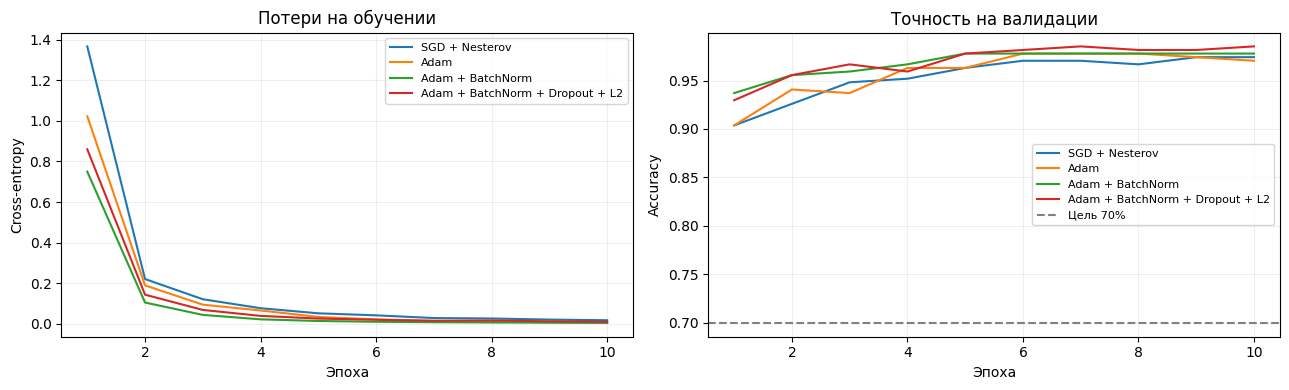

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
print(f'{"Конфигурация":35} {"Эпоха":>7} {"Лучшая val":>12} {"Val, эпоха 10":>15}')
for name, (_, history) in runs.items():
    values = history['val_accuracy']
    epoch = int(np.argmax(values)) + 1
    print(f'{name:35} {epoch:7d} {max(values):12.2%} {values[-1]:15.2%}')
    axes[0].plot(range(1, 11), history['loss'], label=name)
    axes[1].plot(range(1, 11), values, label=name)
axes[0].set(xlabel='Эпоха', ylabel='Cross-entropy', title='Потери на обучении')
axes[1].set(xlabel='Эпоха', ylabel='Accuracy', title='Точность на валидации')
axes[1].axhline(0.7, color='gray', linestyle='--', label='Цель 70%')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

best_name = max(runs, key=lambda name: max(runs[name][1]['val_accuracy']))
best_model, best_history = runs[best_name]
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(reduction='none')
_, test_acc = evaluate_batches(best_model, test_dset, loss_fn)
print(f'Выбрана модель {best_name}.')
print(f'Лучшая валидационная точность: {max(best_history["val_accuracy"]):.2%}.')
print(f'Точность на тесте: {test_acc:.2%}.')
assert max(best_history['val_accuracy']) >= 0.70


## Выводы

Трёхслойная CNN с SGD и импульсом Нестерова 0,9 получила **90,37%** на валидации после первой эпохи. Требование выше 50% выполнено. Одна и та же архитектура Sequential обучена вручную через GradientTape и через compile/fit. К пятой эпохе получено 96,30% и 95,93% соответственно. Оба способа дали близкое качество в этом запуске.

Все четыре конфигурации обучались по 10 эпох на одном разбиении. Везде использовалась категориальная кросс-энтропия для целочисленных меток. В последней конфигурации к целевой функции добавлен L2-штраф. Для сравнения на графике показана кросс-энтропия без этого штрафа.

| Конфигурация | Первая эпоха с лучшей точностью | Лучшая точность на валидации | Точность на 10-й эпохе |
|---|---:|---:|---:|
| SGD + Nesterov | 9 | 97,41% | 97,41% |
| Adam | 6 | 97,78% | 97,04% |
| Adam + BatchNorm | 5 | 97,78% | 97,78% |
| Adam + BatchNorm + Dropout + L2 | 7 | 98,52% | 98,52% |

При переходе от SGD с Нестеровым к Adam с шагом 0,003 изменение лучшей валидационной точности составило +0,37 п. п. При добавлении Batch Normalization к Adam изменение составило +0,00 п. п., а при добавлении Dropout 0,25 и L2 с коэффициентом 0,0001 вместе — +0,74 п. п. Последний эксперимент оценивает совместное действие двух методов регуляризации.

По валидации выбрана конфигурация **Adam + BatchNorm + Dropout + L2**. Цель в 70% достигнута за отведённые 10 эпох. После выбора конфигурации и эпохи модель показала **97,56%** на тестовой выборке.
